# 01-3) 마켓과 머신러닝

> 핵심 키워드: `특성`, `훈련`, `k-최근접 이웃 알고리즘`, `모델`, `정확도`

_"가장 간단한 머신러닝 알고리즘 중 하나인 k-최근접 이웃을 사용여 2개의 종류를 분류하는 머신러닝 모델을 훈련합니다"_

## 생선 분류 문제

### 도미(bream) 데이터 준비

In [34]:
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]

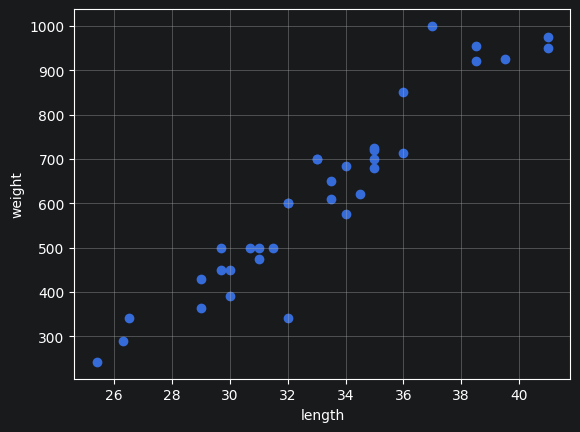

In [35]:
import matplotlib.pyplot as plt

plt.scatter(bream_length, bream_weight)
plt.xlabel('length')
plt.ylabel('weight')
plt.grid(True)
plt.show()

### 빙어(smelt) 데이터 준비

In [36]:
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]

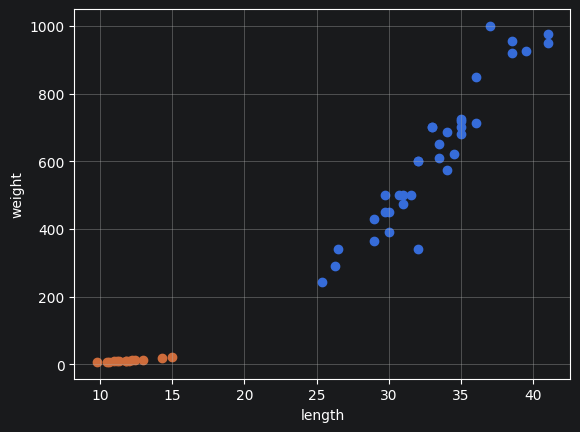

In [37]:
plt.scatter(bream_length, bream_weight)
plt.scatter(smelt_length, smelt_weight)
plt.xlabel('length')
plt.ylabel('weight')
plt.grid(True)
plt.show()

## 첫 번째 머신러닝 프로그램

In [38]:
length = bream_length + smelt_length
weight = bream_weight + smelt_weight

In [39]:
fish_data = [[l, w] for l, w in zip(length, weight)]
print(fish_data)

[[25.4, 242.0], [26.3, 290.0], [26.5, 340.0], [29.0, 363.0], [29.0, 430.0], [29.7, 450.0], [29.7, 500.0], [30.0, 390.0], [30.0, 450.0], [30.7, 500.0], [31.0, 475.0], [31.0, 500.0], [31.5, 500.0], [32.0, 340.0], [32.0, 600.0], [32.0, 600.0], [33.0, 700.0], [33.0, 700.0], [33.5, 610.0], [33.5, 650.0], [34.0, 575.0], [34.0, 685.0], [34.5, 620.0], [35.0, 680.0], [35.0, 700.0], [35.0, 725.0], [35.0, 720.0], [36.0, 714.0], [36.0, 850.0], [37.0, 1000.0], [38.5, 920.0], [38.5, 955.0], [39.5, 925.0], [41.0, 975.0], [41.0, 950.0], [9.8, 6.7], [10.5, 7.5], [10.6, 7.0], [11.0, 9.7], [11.2, 9.8], [11.3, 8.7], [11.8, 10.0], [11.8, 9.9], [12.0, 9.8], [12.2, 12.2], [12.4, 13.4], [13.0, 12.2], [14.3, 19.7], [15.0, 19.9]]


In [40]:
fish_target = [1] * len(bream_length) + [0] * len(smelt_length)
print(fish_target)

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


> 분류 규칙을 찾아내기 위해서 정답지를 작성하는 것!
>
> 1 = 도미(bream), 0 = 빙어(smelt))

머신러닝에서 2개를 구분하는 이진 분류(binary classification)의 경우 찾으려는 대상을 1(positive class)로 놓고 그 외에는 0(negative class)으로 놓는다.

In [41]:
from sklearn.neighbors import KNeighborsClassifier
kn = KNeighborsClassifier()
kn.fit(fish_data, fish_target) # 훈련(training) -> 머신러닝 알고리즘이 데이터에서 규칙을 찾는 과정!
kn.score(fish_data, fish_target) # 평가(0.0 ~ 1.0) -> 정확도(accuracy)를 의미! = (정확히 맞힌 개수) / (전체 데이터 개수)

1.0

> **머신러닝 알고리즘을 구현한 프로그램**을 `모델(model)`이라고 부른다. 또는 프로그램이 아니더라도 **알고리즘을 구체화(수식 등으로)하여 표현**한 것을 모델이라고도 부른다.

In [42]:
kn.predict([[30, 600]])

array([1])

`KNeighborsClassfier` 클래스의 기본 이웃(샘플) 개수는 5.
만약에 `n_neighbors` 매개변수로 참고하는 데이터를 49개로 변경한다면??

In [43]:
kn49 = KNeighborsClassifier(n_neighbors=49) # 참고 데이터를 49개로 한 kn49 모델

In [44]:
kn49.fit(fish_data, fish_target)
kn49.score(fish_data, fish_target)

0.7142857142857143

In [45]:
print(35/49)

0.7142857142857143


y이와 같은 결과가 나타나는 이유는?

kn49 모델은 가장 가까운 데이터 49개를 사용하는 k-NN 알고리즘이기 때문에 fish_data를 적용하면 fish_data에 있는 모든 생선을 이용하여 예측하게 된다.

즉 fish_data의 데이터 49개 중에 도미가 35개로 다수를 차지하므로 어떤 데이터를 넣어도 무조건 도미(bream)로 예측하게 된다.


## 확인 문제

In [50]:
kn = KNeighborsClassifier()
kn.fit(fish_data, fish_target)

for n in range(5, 50):
    # 최근접 이웃 개수 설정
    kn.n_neighbors = n
    # 점수 계산
    score = kn.score(fish_data, fish_target)
    # 100% 정확도에 미치지 못하는 이웃 개수 출력
    if score < 1.0:
        print(f"n_neighbors={n}일 때 정확도: {score:.4f}")


n_neighbors=18일 때 정확도: 0.9796
n_neighbors=19일 때 정확도: 0.9796
n_neighbors=20일 때 정확도: 0.9796
n_neighbors=21일 때 정확도: 0.9796
n_neighbors=22일 때 정확도: 0.9796
n_neighbors=23일 때 정확도: 0.9796
n_neighbors=24일 때 정확도: 0.9796
n_neighbors=25일 때 정확도: 0.9796
n_neighbors=26일 때 정확도: 0.9796
n_neighbors=27일 때 정확도: 0.9796
n_neighbors=28일 때 정확도: 0.9592
n_neighbors=29일 때 정확도: 0.7143
n_neighbors=30일 때 정확도: 0.7143
n_neighbors=31일 때 정확도: 0.7143
n_neighbors=32일 때 정확도: 0.7143
n_neighbors=33일 때 정확도: 0.7143
n_neighbors=34일 때 정확도: 0.7143
n_neighbors=35일 때 정확도: 0.7143
n_neighbors=36일 때 정확도: 0.7143
n_neighbors=37일 때 정확도: 0.7143
n_neighbors=38일 때 정확도: 0.7143
n_neighbors=39일 때 정확도: 0.7143
n_neighbors=40일 때 정확도: 0.7143
n_neighbors=41일 때 정확도: 0.7143
n_neighbors=42일 때 정확도: 0.7143
n_neighbors=43일 때 정확도: 0.7143
n_neighbors=44일 때 정확도: 0.7143
n_neighbors=45일 때 정확도: 0.7143
n_neighbors=46일 때 정확도: 0.7143
n_neighbors=47일 때 정확도: 0.7143
n_neighbors=48일 때 정확도: 0.7143
n_neighbors=49일 때 정확도: 0.7143
